In [1]:
import matplotlib.pyplot as plt
import SWOT_toolbox.SWOT_loader as sload
import SWOT_toolbox.SWOT_tools as stools
import SWOT_toolbox.SWOT_plot as splot
import pandas as pd


In [2]:
swot_path = '/Volumes/tfaraon_PhD/Data/SWOT/download'
path_mnt = '/Volumes/tfaraon_PhD/Data/GIS/Rasters/Armon_Copernicus_D3D_Bathy.tif'

output_folder = "output"


# Single point

In [3]:
lon_point = 137.56
lat_point = -28.893
site_name = 'Belt Bay'

mnt_z = -15.1

#stools.get_mnt_value(stools.load_mnt(path_mnt),lon_point, lat_point)

In [4]:
wse_timeseries_filtered = stools.extract_wse_timeseries_parallel(swot_path, lon_point, lat_point, buffer_size=6,
                                                                 filter_outliers=True, filter_bound=True,
                                                                 wse_qual_filter=[0,1,2,3], mnt_corr=None)


/Users/tfaraon/Documents/PhD_Python/SWOT_WSE_Toolbox/SWOT_toolbox/SWOT_tools.py:119: RuntimeWarning: NetCDF read errors for 8 acquisition(s); 8 without a readable copy. First failed file: /Volumes/tfaraon_PhD/Data/SWOT/download/SWOT_L2_HR_Raster_100m_UTM53J_N_x_x_x_003_435_053F_20230916T112924_20230916T112945_PGC0_01.nc. See read_errors for details.
  result = station(directory_path, lon, lat, **options)


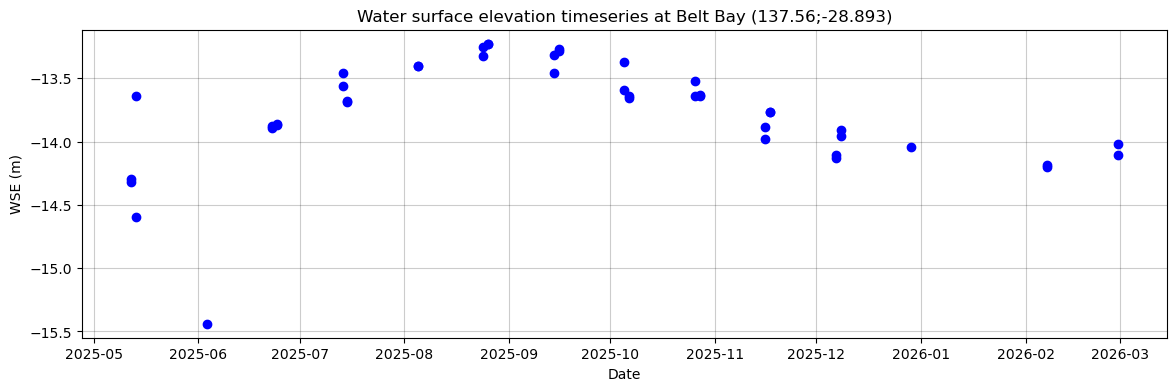

In [8]:

# Filter data between start_date and end_date
wse_timeseries_filtered = wse_timeseries_filtered[
    (wse_timeseries_filtered['date'] >= "2025-01-01") &
    (wse_timeseries_filtered['date'] <= "2026-11-01")
    ]

data_dict = {
    'Filtered': wse_timeseries_filtered
}

splot.plot_timeseries_multiple_mpl(data_dict, lon=lon_point, lat=lat_point,
                                   title=f'Water surface elevation timeseries at {site_name} ({lon_point};{lat_point})',
                                   save_path='SWOT_BB_timeseries.png')


# Profil

In [6]:
coords_list = [
    {"name": "point1", "lon": 137.051, "lat": -28.752},
    {"name": "point2", "lon": 137.040, "lat": -28.801},
    {"name": "point3", "lon": 137.030, "lat": -28.850},
    {"name": "point4", "lon": 137.019, "lat": -28.948},
    {"name": "point5", "lon": 137.009, "lat": -28.948},
    {"name": "point6", "lon": 136.998, "lat": -28.997},
]


/Users/tfaraon/Documents/PhD_Python/SWOT_WSE_Toolbox/SWOT_toolbox/SWOT_tools.py:119: RuntimeWarning: NetCDF read errors for 8 acquisition(s); 8 without a readable copy. First failed file: /Volumes/tfaraon_PhD/Data/SWOT/download/SWOT_L2_HR_Raster_100m_UTM53J_N_x_x_x_003_435_053F_20230916T112924_20230916T112945_PGC0_01.nc. See read_errors for details.
  result = station(directory_path, lon, lat, **options)
/Users/tfaraon/Documents/PhD_Python/SWOT_WSE_Toolbox/SWOT_toolbox/SWOT_tools.py:119: RuntimeWarning: NetCDF read errors for 8 acquisition(s); 8 without a readable copy. First failed file: /Volumes/tfaraon_PhD/Data/SWOT/download/SWOT_L2_HR_Raster_100m_UTM53J_N_x_x_x_003_435_053F_20230916T112924_20230916T112945_PGC0_01.nc. See read_errors for details.
  result = station(directory_path, lon, lat, **options)
/Users/tfaraon/Documents/PhD_Python/SWOT_WSE_Toolbox/SWOT_toolbox/SWOT_tools.py:119: RuntimeWarning: NetCDF read errors for 8 acquisition(s); 8 without a readable copy. First failed fi

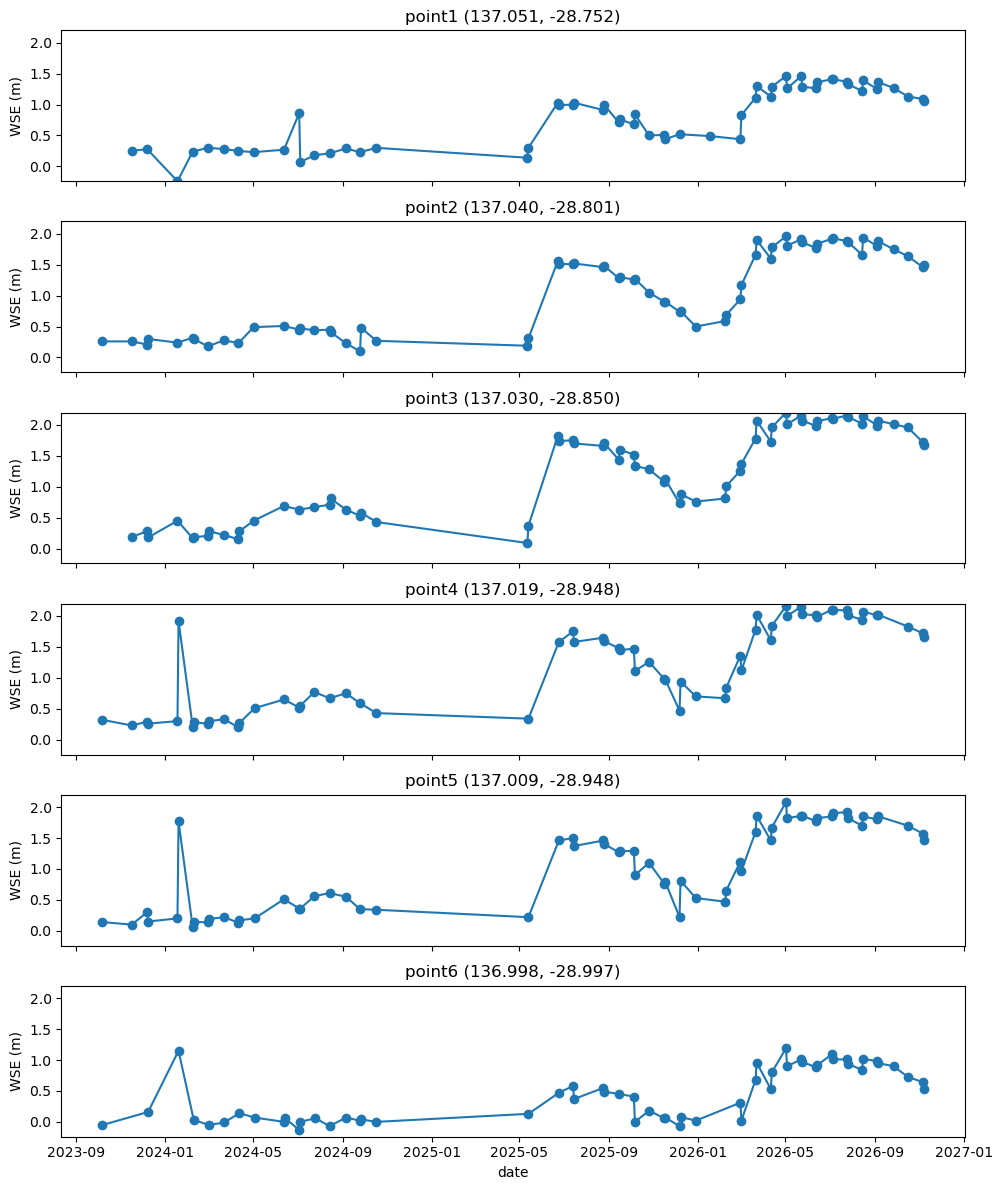

In [7]:
splot.plot_multipoint_WSE_timseries(swot_path, output_folder, coords_list, path_mnt, filter_resolution='100')